Reproduces figures and stats for figure 2 as well as the associated supplemental figure

In [41]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from scipy import stats

def extract_data(folder_path, threshold, key='D'):
    '''
    folder_path = path to folder
    threshold   = speed threshold in um/s
    key         = 'D' (NW166 inducible strain) or 'W' (wild type)

    Walks folder_path, reads every CSV whose name starts with `key`, and bins
    each file into one of four arabinose levels by a digit in the filename:
        2%     -> max   (file[2] == '2')
        0.2%   -> high  (file[4] == '2')
        0.02%  -> mid   (file[5] == '2')
        0.002% -> low   (file[6] == '2')
    For each file it stores the mean speed of cells faster than threshold,
    giving one per-replicate mean. Returns those per-replicate arrays, the SD
    across replicates per level, the pooled cell counts, the replicate
    count, and the cell count per replicate.
    '''
    low_avgs  = []   # 0.002% arabinose - per-replicate mean speeds
    mid_avgs  = []   # 0.02%
    high_avgs = []   # 0.2%
    max_avgs  = []   # 2.0%
    counts_low = [] #unpooled cell counts
    counts_mid = []
    counts_high = []
    counts_max = []
    count_low = 0    # pooled cell counts
    count_mid = 0
    count_high = 0
    count_max = 0
    rep_count = 0    # number of replicates (incremented on the 0.2% branch)

    for root, _, files in os.walk(folder_path):
        for file in files:
            if file.endswith('.csv'):
                file_path = os.path.join(root, file)
                df = pd.read_csv(file_path)

                if file[0] == key:  # only this strain's files
            
                    if file[2] == '2':
                        max_avgs.append(df.iloc[:, 1][df.iloc[:, 1] > threshold].mean())
                        count_max += len(df.iloc[:, 1][df.iloc[:, 1] > threshold])
                        counts_max.append(len(df.iloc[:, 1][df.iloc[:, 1] > threshold]))
                    if file[6] == '2':
                        low_avgs.append(df.iloc[:, 1][df.iloc[:, 1] > threshold].mean())
                        count_low += len(df.iloc[:, 1][df.iloc[:, 1] > threshold])
                        counts_low.append(len(df.iloc[:, 1][df.iloc[:, 1] > threshold]))
                    if file[5] == '2':
                        mid_avgs.append(df.iloc[:, 1][df.iloc[:, 1] > threshold].mean())
                        count_mid += len(df.iloc[:, 1][df.iloc[:, 1] > threshold])
                        counts_mid.append(len(df.iloc[:, 1][df.iloc[:, 1] > threshold]))
                    if file[4] == '2':
                        high_avgs.append(df.iloc[:, 1][df.iloc[:, 1] > threshold].mean())
                        count_high += len(df.iloc[:, 1][df.iloc[:, 1] > threshold])
                        counts_high.append(len(df.iloc[:, 1][df.iloc[:, 1] > threshold]))
                        rep_count += 1

    # SD across replicate means, one per arabinose level.
    low_std  = np.std(low_avgs)
    mid_std  = np.std(mid_avgs)
    high_std = np.std(high_avgs)
    max_std  = np.std(max_avgs)

    unpooled_counts = [counts_low,counts_mid,counts_high,counts_max]

    counts = np.array([count_low, count_mid, count_high, count_max])
    return low_avgs, mid_avgs, high_avgs, max_avgs, low_std, mid_std, high_std, max_std, counts, rep_count, unpooled_counts

In [91]:
# Speed threshold: 4 um/s, the Brownian-motion floor of uninduced ∆MotAB cells.
# Set t = 0 to reproduce the no-threshold supplement version of the figures.
t = 4

# 0% Ficoll
low_avgs, mid_avgs, high_avgs, max_avgs, low_std, mid_std, high_std, max_std, counts, rep_count, c = extract_data('../swimming-cells/NormalMB', t)
low_avgs_W, mid_avgs_W, high_avgs_W, max_avgs_W, low_std_W, mid_std_W, high_std_W, max_std_W, counts_W, rep_count_W, c_W = extract_data('../swimming-cells/NormalMB-WT', t, 'W')
# 10% Ficoll
low_avgs2, mid_avgs2, high_avgs2, max_avgs2, low_std2, mid_std2, high_std2, max_std2, counts2, rep_count2, c2 = extract_data('../swimming-cells/10', t)
low_avgs2_W, mid_avgs2_W, high_avgs2_W, max_avgs2_W, low_std2_W, mid_std2_W, high_std2_W, max_std2_W, counts2_W, rep_count2_W, c2_W = extract_data('../swimming-cells/10', t, 'W')
# 15% Ficoll
low_avgs3, mid_avgs3, high_avgs3, max_avgs3, low_std3, mid_std3, high_std3, max_std3, counts3, rep_count3, c3 = extract_data('../swimming-cells/15', t)
low_avgs3_W, mid_avgs3_W, high_avgs3_W, max_avgs3_W, low_std3_W, mid_std3_W, high_std3_W, max_std3_W, counts3_W, rep_count3_W, c3_W = extract_data('../swimming-cells/15', t, 'W')

In [47]:
#replicate and pooled-cell counts per condition.
for lbl, rc, ct in [('0F NW166', rep_count, counts),
                     ('10F NW166', rep_count2, counts2),
                     ('15F NW166', rep_count3, counts3),
                     ('0F WT', rep_count_W, counts_W),
                     ('10F WT', rep_count2_W, counts2_W),
                     ('15F WT', rep_count3_W, counts3_W)]:
    print(f'{lbl:10s}  replicates(0.2%)={rc}  cells[0.002,0.02,0.2,2%]={ct}')


0F NW166    replicates(0.2%)=6  cells[0.002,0.02,0.2,2%]=[373 158 283 345]
10F NW166   replicates(0.2%)=3  cells[0.002,0.02,0.2,2%]=[204 226 191 232]
15F NW166   replicates(0.2%)=3  cells[0.002,0.02,0.2,2%]=[108 124  90 106]
0F WT       replicates(0.2%)=5  cells[0.002,0.02,0.2,2%]=[522 748 817 989]
10F WT      replicates(0.2%)=3  cells[0.002,0.02,0.2,2%]=[420 526 814 592]
15F WT      replicates(0.2%)=3  cells[0.002,0.02,0.2,2%]=[224 333 629 249]


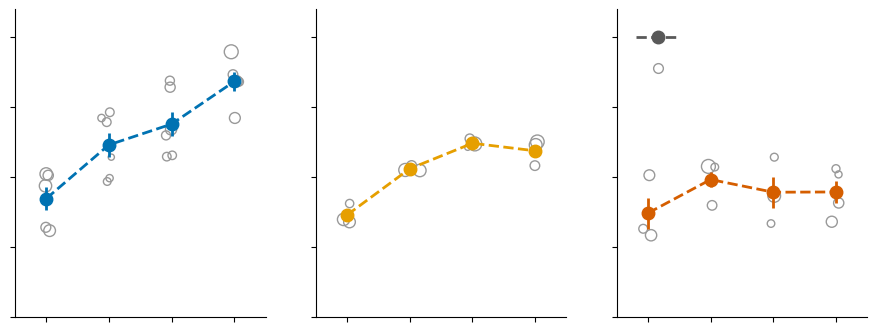

In [93]:
# Figure 3 (main) - swimming speed vs arabinose induction for the NW166
# inducible strain at 0 / 10 / 15% Ficoll. All three panels share one y-axis
# (0-22 um/s) so the slope of the speed-vs-arabinose response can be compared
# directly across load

np.random.seed(527)  # reproducible jitter for the replicate points

# Wong colorblind-safe palette, mapped to Ficoll load
c_0F  = '#0072B2'   # blue       - 0% Ficoll  (low load)
c_10F = '#E69F00'   # orange     - 10% Ficoll (intermediate load)
c_15F = '#D55E00'   # vermillion - 15% Ficoll (high load)

# 0.002 / 0.02 / 0.2 / 2% arabinose - log-spaced, so plotted at equal steps.
arab_pos = [0, 1, 2, 3]
arab_lbl = ['0.002', '0.02', '0.2', '2']


def sem(arr):
    '''Standard error of the mean across replicates.'''
    arr = np.asarray(arr, dtype=float)
    return np.std(arr) / np.sqrt(len(arr))

def scale_size(n,min_count,max_count,max_size=100,min_size=20):
    '''Used to scale size of individual replicate dots'''
    if min_count == max_count:
        return (min_size + max_size) / 2

    return min_size + ((n - min_count) / (max_count - min_count)) * (max_size - min_size)


def plot_speed_panel(ax, series, counts, color, letter, title,
                     show_ylabel=False, show_legend=False):
    '''Draw one fully labelled speed-vs-arabinose panel.
    series: four replicate-mean arrays, ordered low -> max arabinose.'''
    means = [np.mean(a) for a in series]
    errs  = [sem(a) for a in series]

    n_min = min(min(sublist) for sublist in counts)
    n_max = max(max(sublist) for sublist in counts)

    # individual biological-replicate means, jittered, drawn behind the summary
    for x, series_x, count_x in zip(arab_pos, series, counts):
        for avg, n_cells in zip(series_x, count_x):
            xj = np.random.normal(x, 0.06)
            size = scale_size(n_cells,n_min,n_max)
            ax.scatter(xj, avg,s=size, facecolors='none', edgecolors='0.6',linewidths=1.0,zorder=1)

     #condition mean +/- SEM with a dashed eye-guide line (a guide, not a fit)
    ax.errorbar(arab_pos, means, yerr=errs, fmt='o', linestyle='--',
                color=color, capsize=0, markersize=9, lw=2, zorder=3)

    
    # axes
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(0, 22)
    ax.set_xticks(arab_pos)
    ax.set_xticklabels([])
    ax.set_yticks([0, 5, 10, 15, 20],[])

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if show_legend:
        handles = [
            Line2D([0], [0], marker='o', color='0.35', linestyle='--',
                   lw=2, markersize=9),
            Line2D([0], [0], marker='o', markerfacecolor='none',
                   markeredgecolor='0.6', linestyle='none', markersize=7),
        ]
        ax.legend(handles=handles, loc='upper left', fontsize=15.5,
                  frameon=False, handletextpad=0.4)


# Three load panels in a row, sharing the y-axis.
fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(11, 4), sharey=True)

plot_speed_panel(ax_a, [low_avgs,  mid_avgs,  high_avgs,  max_avgs], c,  c_0F,
                 'a', '0% Ficoll')
plot_speed_panel(ax_b, [low_avgs2, mid_avgs2, high_avgs2, max_avgs2], c2, c_10F,
                 'b', '10% Ficoll')
plot_speed_panel(ax_c, [low_avgs3, mid_avgs3, high_avgs3, max_avgs3], c3, c_15F,
                 'c', '15% Ficoll',show_legend=True)

plt.subplots_adjust(wspace=0.2)

plt.savefig('../figure-output/swim-speed.pdf', dpi=600, bbox_inches='tight')
plt.show()

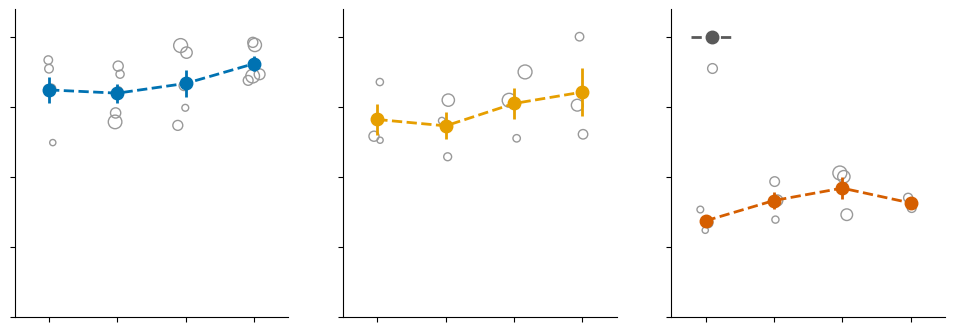

In [83]:
# Supplement - wild-type control across all three Ficoll loads.

np.random.seed(527)  # reproducible jitter

fig, (ax_0, ax_10, ax_15) = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
plot_speed_panel(ax_0, [low_avgs_W, mid_avgs_W, high_avgs_W, max_avgs_W], c_W,
                 c_0F, 'a', 'Wild type, 0% Ficoll',)
plot_speed_panel(ax_10, [low_avgs2_W, mid_avgs2_W, high_avgs2_W, max_avgs2_W], c2_W,
                 c_10F, 'b', 'Wild type, 10% Ficoll')
plot_speed_panel(ax_15, [low_avgs3_W, mid_avgs3_W, high_avgs3_W, max_avgs3_W], c3_W,
                 c_15F, 'c', 'Wild type, 15% Ficoll',show_legend=True)
plt.subplots_adjust(wspace=0.2)

plt.savefig('../figure-output/swim-speed-wt.pdf', dpi=600, bbox_inches='tight')
plt.show()

non-motile average = 3.9891056027164686


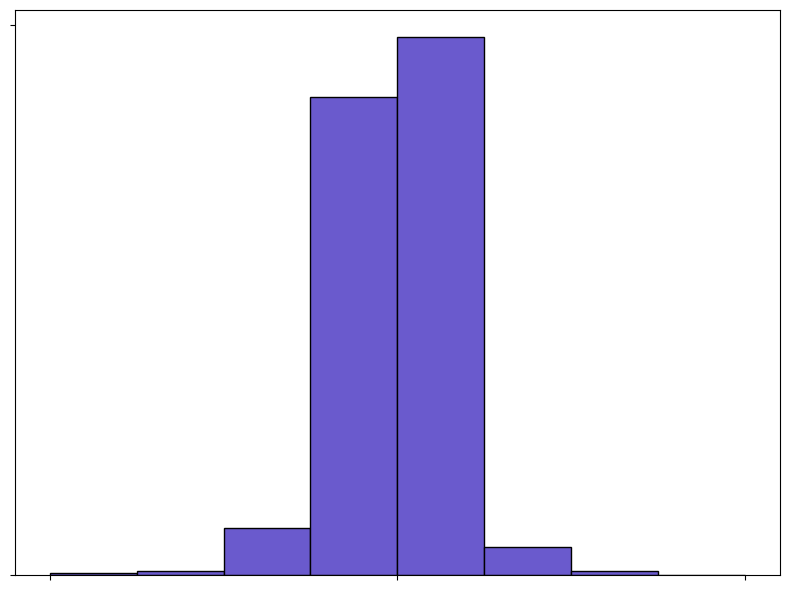

In [17]:
#Plots a distribution of non-motile cells for the supplement
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

directory = '../swimming-cells/NormalMB'
result_array = []

for root, _, files in os.walk(directory):
    for filename in files:
        # Check if the file is a CSV and the third character is '2'
        if filename.endswith(".csv") and len(filename) > 2 and filename[2:7] == '0.000': #change number here
        #if filename.endswith(".csv") and len(filename) > 2:
            filepath = os.path.join(root, filename)
            
            # Read the CSV file
            try:
                df = pd.read_csv(filepath)
                # Ensure there are at least 2 columns
                if df.shape[1] >= 2:
                    # Extract the second column and filter values > 5
                    filtered_values = df.iloc[:, 1][df.iloc[:, 1] > 0].dropna().tolist()
                    result_array += filtered_values
                    
                    
            except Exception as e:
                print(f"Error processing file {filename}: {e}")

bin_edges = [0,1,2,3,4,5,6,7,8]

# Plot histogram
plt.figure(figsize=(8, 6))
plt.hist(result_array, bins=bin_edges, edgecolor='black',color='slateblue',density=True)

plt.yticks([0,0.5],[],fontsize=15)
plt.xticks([0,4,8],[],fontsize=15)
plt.tight_layout()

print(f"non-motile average = {np.mean(result_array)}")
plt.savefig('../figure-output/dist-nonmotile.pdf', dpi=600)

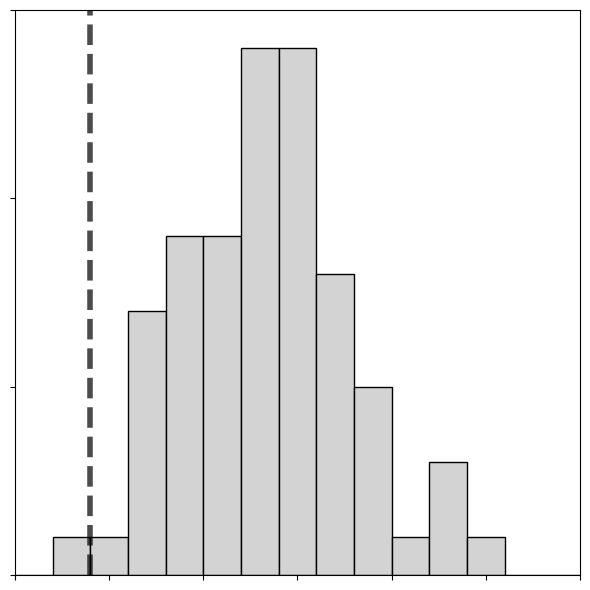

In [15]:
#Plots a distribution of speeds from a specific experiment, used in fig 2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

directory = '../swimming-cells/NormalMB/Z/D_0.200_Z_0.csv'
df = pd.read_csv(directory)
result_array = df["0"].to_numpy()


bin_edges = [0,2,4,6,8,10,12,14,16,18,20,22,24,26,28,30,32,34,36,38]

# Plot histogram
plt.figure(figsize=(6, 6))
plt.hist(result_array, bins=bin_edges, edgecolor='black',color='lightgray',density=False)

plt.xticks((0,5,10,15,20,25,30),[])
plt.xlim(0,30)
plt.axvline(4,c='k',alpha=0.7,linestyle='--',lw=4)





plt.yticks((0,5,10,15),[])
plt.ylim(0,15)

plt.tight_layout()
plt.savefig('../figure-output/dist-motile.pdf', dpi=600)

# ∆s

In [17]:
#calculates ∆s
#original notation while writing manuscript was ∆r_E, now we use ∆s but it is the same value
def delta_R_E(k15,r15,k0,r0):
    '''
    k15 is the array v_k(15%)
    r15 is the array v_r(15%) used as a normalization factor
    k0, r0 are defined similarly
    '''
    rE = np.mean(k15) / np.mean(r15) - np.mean(k0) / np.mean(r0)
    err1 = ((np.std(k15)/len(k15)) / np.mean(k15))**2 + ((np.std(r15)/len(r15)) / np.mean(r15))**2
    err2 = ((np.std(k0)/len(k0)) / np.mean(k0))**2 + ((np.std(r0)/len(r0)) / np.mean(r0))**2
    err = np.sqrt(err1) + np.sqrt(err2)
    return rE, err

In [21]:
#reproduces ∆s(0,10% Ficoll) for swimming cells
dR_max = delta_R_E(max_avgs2,max_avgs2,max_avgs,max_avgs)  
dR_high = delta_R_E(high_avgs2,max_avgs2,high_avgs,max_avgs)  
dR_mid = delta_R_E(mid_avgs2,max_avgs2,mid_avgs,max_avgs)  
dR_low = delta_R_E(low_avgs2,max_avgs2,low_avgs,max_avgs)  
print(f"∆s for 0.002% = {dR_low[0]} +/- {dR_low[1]}")
print(f"∆s for 0.02% = {dR_mid[0]} +/- {dR_mid[1]}")
print(f"∆s for 0.2% = {dR_high[0]} +/- {dR_high[1]}")
print(f"∆s for 2.0% = {dR_max[0]} +/- {dR_max[1]}")

∆s for 0.002% = 0.11134240601395773 +/- 0.08008170287449791
∆s for 0.02% = 0.16133190415434018 +/- 0.05473770207695679
∆s for 0.2% = 0.22608547288026304 +/- 0.053856184642725013
∆s for 2.0% = 0.0 +/- 0.05544252019822177


In [25]:
#reproduces ∆s(15,10% Ficoll) for swimming cells
dR_max = delta_R_E(max_avgs3,max_avgs3,max_avgs2,max_avgs2)  
dR_high = delta_R_E(high_avgs3,max_avgs3,high_avgs2,max_avgs2)  
dR_mid = delta_R_E(mid_avgs3,max_avgs3,mid_avgs2,max_avgs2)  
dR_low = delta_R_E(low_avgs3,max_avgs3,low_avgs2,max_avgs2)  
print(f"∆s for 0.002% = {dR_low[0]} +/- {dR_low[1]}")
print(f"∆s for 0.02% = {dR_mid[0]} +/- {dR_mid[1]}")
print(f"∆s for 0.2% = {dR_high[0]} +/- {dR_high[1]}")
print(f"∆s for 2.0% = {dR_max[0]} +/- {dR_max[1]}")

∆s for 0.002% = 0.2169722027182962 +/- 0.13031675990497738
∆s for 0.02% = 0.20688524220836613 +/- 0.07339442217606425
∆s for 0.2% = -0.047446074705832064 +/- 0.10665026408195787
∆s for 2.0% = 0.0 +/- 0.0907531065190963


# Stats

In [15]:
from scipy import stats
from statsmodels.stats.weightstats import ttost_ind, DescrStatsW, CompareMeans
#calculates ANOVA p-values for ∆motAB + pBAD33 strain
#ANOVA FOR 0%
fvalue, pvalue = stats.f_oneway(max_avgs,high_avgs,mid_avgs,low_avgs)
print(f"0% Ficoll P-value (ANOVA): {pvalue}")

#ANOVA FOR 10%
fvalue, pvalue = stats.f_oneway(max_avgs2,high_avgs2,mid_avgs2,low_avgs2)
print(f"10% Ficoll P-value (ANOVA): {pvalue}")

#ANOVA FOR 15%
fvalue, pvalue = stats.f_oneway(max_avgs3,high_avgs3,mid_avgs3,low_avgs3)
print(f"15% Ficoll P-value (ANOVA): {pvalue}")


0% Ficoll P-value (ANOVA): 7.033660908402092e-05
10% Ficoll P-value (ANOVA): 2.9370903817983297e-05
15% Ficoll P-value (ANOVA): 0.47788785322836586


In [17]:
#calculates ANOVA p-values for WT
#ANOVA FOR 0%
fvalue, pvalue = stats.f_oneway(max_avgs_W,high_avgs_W,mid_avgs_W,low_avgs_W)
print(f"WT 0% Ficoll P-value (ANOVA): {pvalue}")

#ANOVA FOR 10%
fvalue, pvalue = stats.f_oneway(max_avgs2_W,high_avgs2_W,mid_avgs2_W,low_avgs2_W)
print(f"WT 10% Ficoll P-value (ANOVA): {pvalue}")

#ANOVA FOR 15%
fvalue, pvalue = stats.f_oneway(max_avgs3_W,high_avgs3_W,mid_avgs3_W,low_avgs3_W)
print(f"WT 15% Ficoll P-value (ANOVA): {pvalue}")


WT 0% Ficoll P-value (ANOVA): 0.37066791571491414
WT 10% Ficoll P-value (ANOVA): 0.6843197337020213
WT 15% Ficoll P-value (ANOVA): 0.17638039312798812


In [31]:
def TOST(lower,upper,x,y,alpha=0.1):
    #function to calculate TOST
    p_val, res1, res2 = ttost_ind(x, y, low=lower, upp=upper, usevar="unequal")
    
    # Mean difference (Delta)
    delta = np.mean(x) - np.mean(y)

    # Welch confidence interval for difference
    x_stats = DescrStatsW(x)
    y_stats = DescrStatsW(y)

    cm = CompareMeans(x_stats, y_stats)

    ci_low, ci_high = cm.tconfint_diff(
        alpha=alpha,
        usevar="unequal"
    )

    return round(delta,3), (round(ci_low,3), round(ci_high,3)), round(p_val,3)

In [33]:
#TOST
print("∆, CI, p-value")
print(f"15F 2e0 vs 2e1: {TOST(-3,3,max_avgs3,high_avgs3)}")
print(f"15F 2e2 vs 2e3: {TOST(-3,3,mid_avgs3,low_avgs3)}")
print(f"15F 2e1 vs 2e2: {TOST(-3,3,mid_avgs3,high_avgs3)}")
print(f"15F 2e0 vs 2e2: {TOST(-3,3,max_avgs3,mid_avgs3)}")
print(f"15F 2e0 vs 2e3: {TOST(-3,3,max_avgs3,low_avgs3)}")
print(f"15F 2e1 vs 2e3: {TOST(-3,3,high_avgs3,low_avgs3)}")
print(f"10F 2e0 vs 2e1: {TOST(-3,3,high_avgs2,max_avgs2)}")

∆, CI, p-value
15F 2e0 vs 2e1: (0.019, (-3.585, 3.624), 0.075)
15F 2e2 vs 2e3: (2.397, (-1.19, 5.983), 0.358)
15F 2e1 vs 2e2: (0.907, (-2.725, 4.539), 0.133)
15F 2e0 vs 2e2: (-0.888, (-3.063, 1.287), 0.054)
15F 2e0 vs 2e3: (1.509, (-2.056, 5.074), 0.208)
15F 2e1 vs 2e3: (1.49, (-2.632, 5.612), 0.239)
10F 2e0 vs 2e1: (0.538, (-0.917, 1.994), 0.017)
